<a href="https://colab.research.google.com/github/miguelorduna360-alt/Debt/blob/main/MiguelO'sWritten_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pre and Post 2008 Recession Research**

# **Abstract**
---
The 2008 recession was a bad time for the USA but that begs the question if other economies were affected. The research question I came up with was, To what extent was the economic performance of the United States throughout the 2008 recession an indicator of change in terms of total private debt, household debt and Non-Financial Corporation Debt for European and Asian economies?

I used Total private debt, Household debt, Non-financial Corporation Debt, all of them being for Loans and debt securities. I tested the P-values with comparing the USA dataset with the FiliteredDebt for all 11 foreign countries, to then doing four linear regression models, Three being individual and one focusing on all three debt sectors that I chose.

The P values proved my hypothesis had weight to it and rejected the null, although my machine models were a bit different. all being average of below average and the final being below average, although beforehand they all tested with 0.70 or higher.


The P values indicate that my hypothesis has significant weight and can answer my research question that the USA does have a significant influence in the European and Asian economies. The model training doesn't have the best accuracy due to the fact that most of the dataset was filled with null values and needed more countries that had more values between 2006 to 2012 to be selected.

# Background

---


The context of my research takes place between 2006 to 2012, enough years to
have a pre-recession of 2008 timeline that spans from 2006 to 2007, to having the 2008 recession that lasted from 2008 to 2009, and having a post 2008 recession that spans from 2009 to 2012. The Data itself comes from https://www.imf.org/external/datamapper/datasets/GDD and measures various debt sectors from 1950 to 2023, .
The research question I came up with was, To what extent was the economic performance of the United States throughout the 2008 recession an indicator of change in terms of total private debt, household debt and Non-Financial Corporation Debt for European and Asian economies?
The hypothesis: USA Economy has great influence on the european and Asian Economies.
For the purpose of the study, I included five asian countries and six european countries that all had data for 2006 to 2012.

In [ ]:
# Tools and Libararies utilized
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import SelectKBest
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score

## Various Datasets for European and Asian countries

In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/USADataSet%20-%20GlobalDebtDatabaseForUS.xlsx%20-%20Data%20(2).csv'
debtUSA_df = pd.read_csv(url)
debtUSA_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,75.83,55.31,25.48,24.80,50.34,30.51,83.13,78.20,301.78
1,1951,72.69,53.66,24.52,23.91,48.17,29.75,72.96,68.20,348.99
2,1952,88.24,56.56,26.60,25.98,61.64,30.58,72.53,66.34,368.03
3,1953,88.05,58.02,28.43,27.79,59.62,30.22,71.75,64.60,389.15
4,1954,106.06,62.57,31.54,30.86,74.52,31.71,73.57,64.96,390.28
...,...,...,...,...,...,...,...,...,...,...
69,2019,229.96,153.39,77.05,75.11,152.91,78.28,108.71,92.39,21539.98
70,2020,238.75,164.80,80.48,78.46,158.28,86.33,132.93,116.88,21354.13
71,2021,229.76,160.50,79.51,77.75,150.25,82.76,125.25,111.90,23681.18
72,2022,227.77,156.12,76.63,75.47,151.14,80.65,119.52,107.54,26006.90


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/UK%20Dataset%20-%20GlobalDebtDatabaseForUK.xlsx%20-%20Data.csv'
debtUK_df = pd.read_csv(url)
debtUK_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,179.90,NaN,14.34
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,162.18,NaN,15.98
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,150.15,NaN,17.24
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,140.87,NaN,18.49
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,135.84,NaN,19.57
...,...,...,...,...,...,...,...,...,...,...
69,2019,200.10,156.99,91.00,85.70,109.10,71.28,85.66,84.69,2233.92
70,2020,226.79,176.68,99.39,92.91,127.40,83.78,105.84,104.85,2103.49
71,2021,199.81,163.85,92.82,87.94,106.99,75.91,105.14,104.31,2285.40
72,2022,170.77,148.45,87.31,82.46,83.46,65.99,99.62,99.01,2526.43


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/CN%20Dataset%20-%20GlobalDebtDatabaseForChina.xlsx%20-%20Data.csv'
debtCN_df = pd.read_csv(url)
debtCN_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.51
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.30
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,84.13
...,...,...,...,...,...,...,...,...,...,...
69,2019,NaN,186.37,NaN,55.85,NaN,130.52,60.40,NaN,99070.84
70,2020,NaN,198.69,NaN,61.61,NaN,137.08,70.16,NaN,102562.84
71,2021,NaN,192.81,NaN,62.09,NaN,130.72,71.85,NaN,114528.29
72,2022,NaN,198.53,NaN,62.32,NaN,136.21,77.39,NaN,120247.10


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/JP%20Dataset%20-%20GlobalDebtDatabaseForUS.xlsx%20-%20Data%20(2).csv'
debtJP_df = pd.read_csv(url)
debtJP_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4167.77
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5772.23
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6516.18
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7354.44
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8166.46
...,...,...,...,...,...,...,...,...,...,...
69,2019,205.88,164.33,64.79,62.54,141.08,101.79,236.38,197.46,557910.90
70,2020,222.39,183.25,69.52,67.49,152.87,115.76,258.37,205.56,539648.80
71,2021,224.51,183.62,69.49,67.65,155.02,115.97,253.65,214.10,553150.80
72,2022,229.43,185.53,70.00,67.85,159.44,117.68,256.30,214.26,561751.30


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/ES%20Dataset%20-%20GlobalDebtDatabaseForUS.xlsx%20-%20Data%20(1).csv'
debtES_df = pd.read_csv(url)
debtES_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.05,1.66
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.81,2.09
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.76,2.16
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.15,2.11
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.80,2.45
...,...,...,...,...,...,...,...,...,...,...
69,2019,195.47,148.68,60.43,56.44,135.04,92.24,97.58,87.40,1253.71
70,2020,217.80,168.68,66.45,62.02,151.34,106.66,119.18,106.85,1129.21
71,2021,205.26,159.17,61.50,57.00,143.77,102.17,115.59,103.62,1235.47
72,2022,184.87,141.56,55.65,51.22,129.22,90.33,109.40,98.93,1373.63


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/DK%20Dataset%20-%20GlobalDebtDatabaseForDK.xlsx%20-%20Data.csv'
debtDK_df = pd.read_csv(url)
debtDK_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.32,22.72
1,1951,NaN,85.40,NaN,NaN,NaN,NaN,NaN,41.07,24.16
2,1952,NaN,82.95,NaN,NaN,NaN,NaN,NaN,38.71,25.86
3,1953,NaN,81.07,NaN,NaN,NaN,NaN,NaN,36.12,27.82
4,1954,NaN,81.20,NaN,NaN,NaN,NaN,NaN,29.38,29.15
...,...,...,...,...,...,...,...,...,...,...
69,2019,299.75,248.13,116.59,110.93,183.16,137.20,33.79,26.59,2303.64
70,2020,288.23,237.38,118.85,111.72,169.38,125.67,42.17,34.66,2326.59
71,2021,268.29,227.49,107.42,101.42,160.87,126.07,35.78,28.32,2567.52
72,2022,258.09,217.29,88.75,84.46,169.34,132.83,29.70,22.67,2844.23


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/THA%20Dataset%20-%20GlobalDebtDatabaseForThailand.xlsx%20-%20Data.csv'
debtTHA_df = pd.read_csv(url)
debtTHA_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.55,26.22
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.89,29.16
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.16,31.76
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.83,33.01
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.52,35.26
...,...,...,...,...,...,...,...,...,...,...
69,2019,NaN,159.51,NaN,79.87,NaN,79.64,34.05,34.00,16889.17
70,2020,NaN,180.91,NaN,89.58,NaN,91.34,45.10,45.05,15661.29
71,2021,NaN,184.27,NaN,90.04,NaN,94.22,52.77,52.73,16188.61
72,2022,NaN,178.71,NaN,87.01,NaN,91.70,53.74,53.53,17378.02


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/NL%20Dataset%20-%20GlobalDebtDatabaseForUS.xlsx%20-%20Data.csv'
debtNL_df = pd.read_csv(url)
debtNL_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,143.73,NaN,9.05
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,123.93,NaN,10.33
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,111.85,NaN,10.78
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,106.24,NaN,11.47
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,92.86,NaN,12.81
...,...,...,...,...,...,...,...,...,...,...
69,2019,350.57,244.66,113.34,98.77,237.22,145.89,47.58,NaN,829.77
70,2020,367.68,246.67,118.27,102.39,249.41,144.28,53.34,NaN,816.46
71,2021,353.88,234.15,112.42,97.62,241.46,136.54,50.44,NaN,891.55
72,2022,333.23,216.77,105.15,90.12,228.07,126.64,48.35,NaN,993.82


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/SE%20Dataset%20-%20GlobalDebtDatabaseForGER.xlsx%20-%20Data%20(1).csv'
debtSE_df = pd.read_csv(url)
debtSE_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,37.31,NaN,NaN,NaN,36.11,35.68
1,1951,NaN,NaN,NaN,32.64,NaN,NaN,NaN,30.04,43.95
2,1952,NaN,NaN,NaN,32.45,NaN,NaN,NaN,27.42,47.79
3,1953,NaN,NaN,NaN,34.85,NaN,NaN,NaN,27.20,49.43
4,1954,NaN,NaN,NaN,36.24,NaN,NaN,NaN,27.70,52.36
...,...,...,...,...,...,...,...,...,...,...
69,2019,264.66,225.15,92.02,88.51,172.63,136.64,35.70,36.63,5033.44
70,2020,279.38,238.95,97.78,93.65,181.60,145.30,40.31,42.25,5020.98
71,2021,283.93,242.23,95.94,91.86,188.00,150.37,36.83,38.98,5464.88
72,2022,288.19,239.90,92.86,87.54,195.32,152.36,33.75,37.42,5865.21


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/IN%20Dataset%20-%20GlobalDebtDatabaseForIndia.xlsx%20-%20Data.csv'
debtIN_df = pd.read_csv(url)
debtIN_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.13,128.04
1,1951,NaN,16.82,NaN,NaN,NaN,NaN,NaN,25.18,135.08
2,1952,NaN,16.76,NaN,NaN,NaN,NaN,NaN,26.39,132.06
3,1953,NaN,16.21,NaN,NaN,NaN,NaN,NaN,24.65,139.65
4,1954,NaN,18.65,NaN,NaN,NaN,NaN,NaN,24.86,130.45
...,...,...,...,...,...,...,...,...,...,...
69,2019,NaN,94.54,NaN,36.00,NaN,58.54,75.04,46.70,201035.90
70,2020,NaN,101.60,NaN,40.43,NaN,61.18,88.43,55.03,198541.00
71,2021,NaN,90.60,NaN,36.05,NaN,54.55,83.49,54.42,235974.00
72,2022,NaN,93.80,NaN,37.32,NaN,56.48,81.68,54.36,269496.50


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/HK%20Dataset%20-%20GlobalDebtDatabaseForHongKong.xlsx%20-%20Data.csv'
debtHK_df = pd.read_csv(url)
debtHK_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
69,2019,NaN,349.45,NaN,81.68,NaN,267.78,NaN,6.17,2845.02
70,2020,NaN,384.04,NaN,91.61,NaN,292.43,NaN,8.36,2675.79
71,2021,NaN,368.81,NaN,93.14,NaN,275.67,NaN,10.73,2867.97
72,2022,NaN,374.05,NaN,96.36,NaN,277.69,NaN,14.60,2808.98


In [ ]:
url = 'https://raw.githubusercontent.com/miguelorduna360-alt/DebtData/refs/heads/main/GER%20dataset%20-%20GlobalDebtDatabaseForGER.xlsx%20-%20Data.csv'
debtGER_df = pd.read_csv(url)
debtGER_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product
0,1950,NaN,33.38,NaN,NaN,NaN,NaN,18.81,NaN,56.08
1,1951,NaN,35.19,NaN,NaN,NaN,NaN,16.69,NaN,68.53
2,1952,NaN,40.11,NaN,NaN,NaN,NaN,15.71,NaN,78.28
3,1953,NaN,46.79,NaN,NaN,NaN,NaN,20.56,NaN,84.30
4,1954,NaN,53.95,NaN,NaN,NaN,NaN,21.81,NaN,90.72
...,...,...,...,...,...,...,...,...,...,...
69,2019,164.81,120.00,53.10,52.55,111.72,67.45,58.56,37.13,3534.88
70,2020,175.07,129.27,56.84,56.28,118.23,73.00,67.86,44.25,3449.62
71,2021,178.00,128.11,56.10,55.55,121.90,72.56,67.88,45.68,3676.46
72,2022,173.83,125.39,54.47,53.88,119.36,71.51,64.79,44.92,3953.85


In [ ]:
#United States of America Dataset
debtUSA_df = debtUSA_df.apply(pd.to_numeric, errors='coerce')
debtUSA_df.fillna(0, inplace=True)
#United Kingdom Dataset
debtUK_df = debtUK_df.apply(pd.to_numeric, errors='coerce')
debtUK_df.fillna(0, inplace=True)
# China Dataset
debtCN_df = debtCN_df.apply(pd.to_numeric, errors='coerce')
debtCN_df.fillna(0, inplace=True)
# Japan Dataset
debtJP_df = debtJP_df.apply(pd.to_numeric, errors='coerce')
debtJP_df.fillna(0, inplace=True)
#Spain Dataset
debtES_df = debtES_df.apply(pd.to_numeric, errors='coerce')
debtES_df.fillna(0, inplace=True)
#Denmark Dataset
debtDK_df = debtDK_df.apply(pd.to_numeric, errors='coerce')
debtDK_df.fillna(0, inplace=True)
#Hong Kong Dataset
debtHK_df = debtHK_df.apply(pd.to_numeric, errors='coerce')
debtHK_df.fillna(0, inplace=True)
#Netherlands Dataset
debtNL_df = debtNL_df.apply(pd.to_numeric, errors='coerce')
debtNL_df.fillna(0, inplace=True)
#India Dataset
debtIN_df = debtIN_df.apply(pd.to_numeric, errors='coerce')
debtIN_df.fillna(0, inplace=True)
#Thailand Dataset
debtTHA_df = debtTHA_df.apply(pd.to_numeric, errors='coerce')
debtTHA_df.fillna(0, inplace=True)
#Germany Dataset
debtGER_df = debtGER_df.apply(pd.to_numeric, errors='coerce')
debtGER_df.fillna(0, inplace=True)
#Sweden Dataset
debtSE_df = debtSE_df.apply(pd.to_numeric, errors='coerce')
debtSE_df.fillna(0, inplace=True)

In [ ]:
debtUK_df['Country'] = 'UK'
debtCN_df['Country'] = 'CN'
debtJP_df['Country'] = 'JP'
debtES_df['Country'] = 'ES'
debtSE_df['Country'] = 'SE'
debtDK_df['Country'] = 'DK'
debtHK_df['Country'] = 'HK'
debtNL_df['Country'] = 'NL'
debtIN_df['Country'] = 'IN'
debtTHA_df['Country'] = 'THA'
debtGER_df['Country'] = 'GER'

combinded_df = pd.concat([debtUK_df, debtCN_df, debtJP_df, debtES_df, debtDK_df, debtHK_df, debtNL_df, debtIN_df, debtTHA_df, debtGER_df, debtSE_df])

filteredDebt_df = combinded_df[(combinded_df['Year'] >= 2006) & (combinded_df['Year'] <= 2012)]

filtered_debtUSA_df = debtUSA_df[(debtUSA_df['Year'] >= 2006) & (debtUSA_df['Year'] <= 2012)]
filtered_debtUSA_df['Country'] = 'USA'

finalizedDebt_df = pd.concat([filtered_debtUSA_df, filteredDebt_df])
finalizedDebt_df

,Year,"Total private debt, all instruments","Total private debt, loans and debt securities","Household debt, all instruments","Household debt, loans and debt securities","Non-financial corporations debt, all instruments","Non-financial corporations debt, loans and debt securities",General government debt,Central government debt,Nominal gross domestic product,Country
56,2006,222.89,164.09,98.71,96.92,124.18,67.17,65.91,44.83,13815.60,USA
57,2007,230.98,170.86,100.59,98.74,130.38,72.12,66.25,45.17,14474.25,USA
58,2008,235.93,170.76,98.15,96.15,137.79,74.61,74.97,53.41,14769.85,USA
59,2009,235.52,169.54,99.24,96.96,136.29,72.59,87.80,64.97,14478.05,USA
60,2010,226.49,160.69,93.76,91.73,132.73,68.96,96.12,73.65,15048.98,USA
...,...,...,...,...,...,...,...,...,...,...,...
58,2008,229.85,188.05,73.26,68.25,156.60,119.80,37.74,41.14,3391.89,SE
59,2009,241.52,201.21,80.36,75.59,161.16,125.63,40.95,44.63,3324.15,SE
60,2010,230.18,189.32,81.07,75.92,149.11,113.40,38.30,41.19,3551.53,SE
61,2011,232.76,192.89,81.20,76.50,151.57,116.39,37.38,39.99,3704.84,SE


# Results

## Graph One: USA and The Eleven Countries Comparsion in Total Private Debt

---
I wanted to see how the USA compared with other countries in terms of Household debt via on a graph. It seems the USA is slightly middle to above in this graph while china and india are below in terms of Household debt.


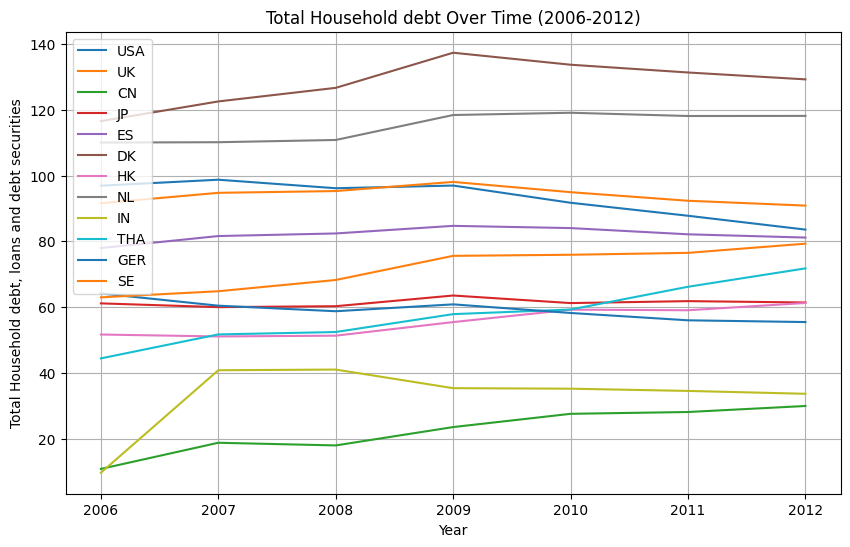

In [ ]:
plt.figure(figsize=(10, 6))


for country in finalizedDebt_df['Country'].unique():
    country_data = finalizedDebt_df[finalizedDebt_df['Country'] == country]
    plt.plot(country_data['Year'], country_data['Household debt, loans and debt securities'], label=country)


plt.xlabel('Year')
plt.ylabel('Total Household debt, loans and debt securities')
plt.title('Total Household debt Over Time (2006-2012)')
plt.legend()
plt.grid(True)
plt.show()

## Graph Two: USA and The Eleven Countries Comparsion in Household Debt

---
I visualized the graph for total private debt over time from 2006 to 2012 as the USA seemed to be in the middle while other countries seemed to follow along. India also to have appeared to fall below the USA whilst other countries were above USA in Total private Debt.


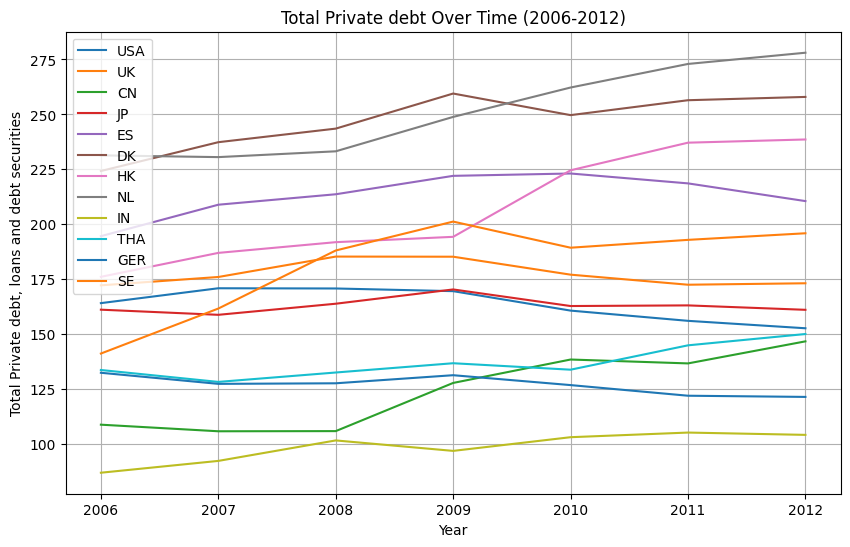

In [ ]:
plt.figure(figsize=(10, 6))

for country in finalizedDebt_df['Country'].unique():
    country_data = finalizedDebt_df[finalizedDebt_df['Country'] == country]
    plt.plot(country_data['Year'], country_data['Total private debt, loans and debt securities'], label=country)


plt.xlabel('Year')
plt.ylabel('Total Private debt, loans and debt securities')
plt.title('Total Private debt Over Time (2006-2012)')
plt.legend()
plt.grid(True)
plt.show()

## Graph Three: USA and The Eleven Countries Comparsion in Nonfinancial Coropration Debt

---
I visualized a graph for the nonfiancial Corporation debt and I noticed that the USA was lower in this graph whilst most of the other countries were above the USA. The only country that fell below was India whilst the other countries rose higher in nonfinancial Corporation Debt.


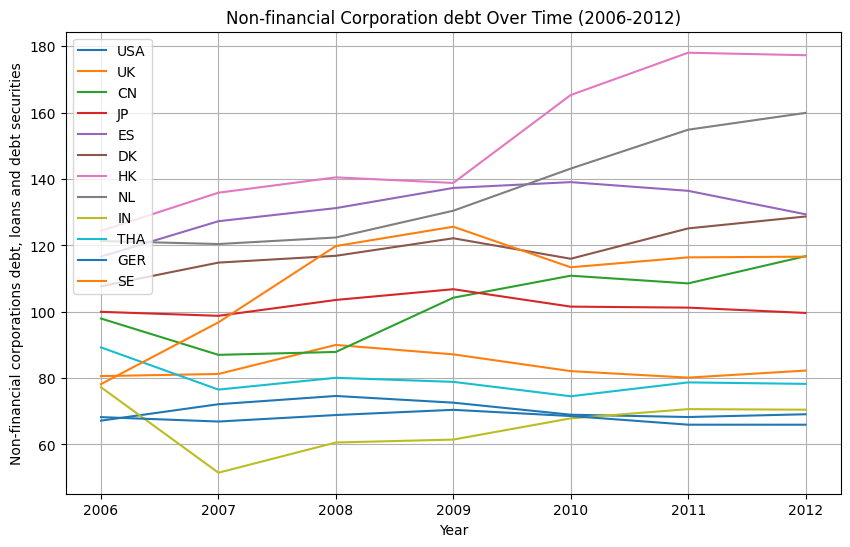

In [ ]:
plt.figure(figsize=(10, 6))

for country in finalizedDebt_df['Country'].unique():
    country_data = finalizedDebt_df[finalizedDebt_df['Country'] == country]
    plt.plot(country_data['Year'], country_data['Non-financial corporations debt, loans and debt securities'], label=country)


plt.xlabel('Year')
plt.ylabel('Non-financial corporations debt, loans and debt securities')
plt.title('Non-financial Corporation debt Over Time (2006-2012)')
plt.legend()
plt.grid(True)
plt.show()

## Linear Regression Model

In [ ]:
from sklearn.linear_model import LinearRegression

### Linear Regression: Household debt, loans and debt securities

---
I trained a linear regression model for Household debt, loans and debt securities to get the values i would get out of the three. It's safe to say that this model was the best performing one with an r2 score of 0.78.


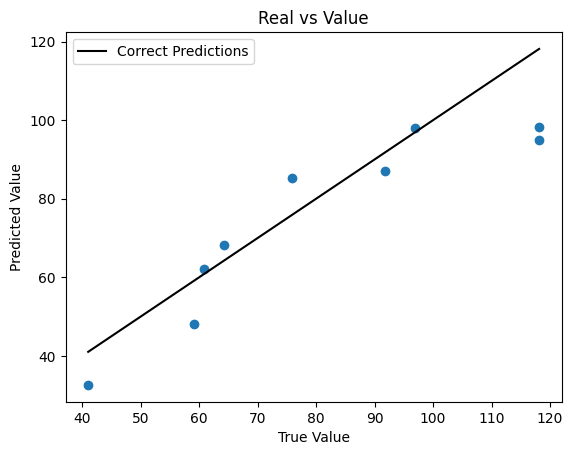

R2 Score: 0.7877095145947628
MSE: 139.660003955045
MAE: 9.204049694552152


In [ ]:
x = finalizedDebt_df.drop(columns = ['Year', 'Country', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities', 'Non-financial corporations debt, loans and debt securities'])
y = finalizedDebt_df['Household debt, loans and debt securities']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

model_1 = LinearRegression()
model_1.fit(X_train, y_train)
predictions = model_1.predict(X_test)

plt.scatter(y_test, predictions)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = 'black', label='Correct Predictions')


plt.xlabel('True Value')
plt.ylabel('Predicted Value')
plt.title('Real vs Value')
plt.legend()

plt.show()

print("R2 Score:", r2_score(y_test, predictions))

print("MSE:", mean_squared_error(y_test, predictions))

print("MAE:", mean_absolute_error(y_test, predictions))

### Linear Regression: Total Private Debt, loans and debt securities

---
I trained a regression model for the Total private debt, out of the three individual models, this one had the worst performance. It came back with an R2 score of 0.64 and was a subpar training model. It has the highest MSE error score of 1287 and an MAE of 29.

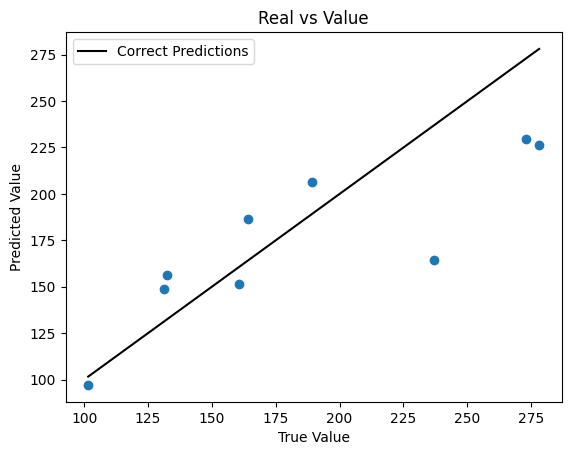

R2 Score: 0.6463668655114612
MSE: 1287.8993633880914
MAE: 29.098405049034355


In [ ]:
x = finalizedDebt_df.drop(columns = ['Year', 'Country', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities', 'Non-financial corporations debt, loans and debt securities'])
y = finalizedDebt_df['Total private debt, loans and debt securities']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

model_1 = LinearRegression()
model_1.fit(X_train, y_train)
predictions = model_1.predict(X_test)

plt.scatter(y_test, predictions)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = 'black', label='Correct Predictions')


plt.xlabel('True Value')
plt.ylabel('Predicted Value')
plt.title('Real vs Value')
plt.legend()

plt.show()

print("R2 Score:", r2_score(y_test, predictions))

print("MSE:", mean_squared_error(y_test, predictions))

print("MAE:", mean_absolute_error(y_test, predictions))

### Linear Regression: Nonfinancial Corporations debt

---
I trained a linear regression model for the Nonfinancial Corporations debt, which out of the three, was the second in betweem Total private and Household. It does unfortunately share the flaws of Total private debt with an R2 score of 0.64 but also has less MAE and MSE error values.


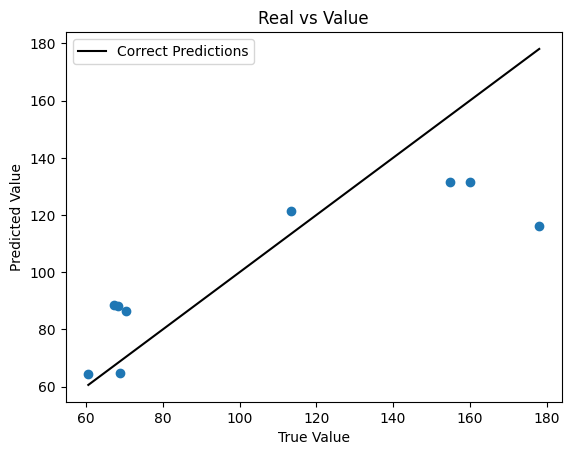

R2 Score: 0.6495665860978437
MSE: 707.3176095484946
MAE: 20.77352580496895


In [ ]:
x = finalizedDebt_df.drop(columns = ['Year', 'Country', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities', 'Non-financial corporations debt, loans and debt securities'])
y = finalizedDebt_df['Non-financial corporations debt, loans and debt securities']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

model_1 = LinearRegression()
model_1.fit(X_train, y_train)
predictions = model_1.predict(X_test)

plt.scatter(y_test, predictions)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = 'black', label='Correct Predictions')


plt.xlabel('True Value')
plt.ylabel('Predicted Value')
plt.title('Real vs Value')
plt.legend()

plt.show()

print("R2 Score:", r2_score(y_test, predictions))

print("MSE:", mean_squared_error(y_test, predictions))

print("MAE:", mean_absolute_error(y_test, predictions))

### Linear Regression: All Three

---
I trained a linear regression model on all three(Non-financial corporations debt, loans and debt securities', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities) to see the values I would gain from testing all three. I will say that this performed very different, it was at a value of 0.72 and went down to 0.69 which means the model is decent to subpar.

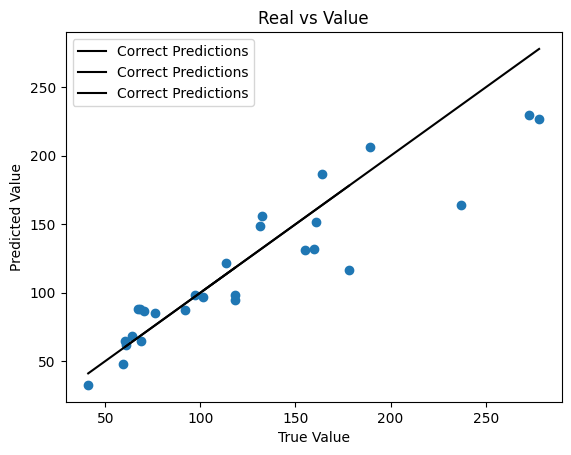

R2 Score: 0.6945476554014065
MSE: 711.6256589638465
MAE: 19.69199351618514


In [ ]:
x = finalizedDebt_df.drop(columns = ['Year', 'Country', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities', 'Non-financial corporations debt, loans and debt securities'])
y = finalizedDebt_df[['Non-financial corporations debt, loans and debt securities', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities']]

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

model_1 = LinearRegression()
model_1.fit(X_train, y_train)
predictions = model_1.predict(X_test)

plt.scatter(y_test, predictions)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = 'black', label='Correct Predictions')


plt.xlabel('True Value')
plt.ylabel('Predicted Value')
plt.title('Real vs Value')
plt.legend()

plt.show()

print("R2 Score:", r2_score(y_test, predictions))

print("MSE:", mean_squared_error(y_test, predictions))

print("MAE:", mean_absolute_error(y_test, predictions))

### Hypothesis Test

This is where I began to test my hypothesis, i compared both the USA and the Asian European combined datasets to get the P value for all three debt sectors. The results came back extremely Significant with all p-values being < 0.05 (Less than 0.05), which meant i was able to reject the null. This meant that my hypothesis had significant weight to it and was able to prove that USA economic performance had great influence on the european and asian economies.


In [ ]:
from scipy.stats import levene

usa_values = filtered_debtUSA_df[['Non-financial corporations debt, loans and debt securities', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities']]
foreign_values = filteredDebt_df[['Non-financial corporations debt, loans and debt securities', 'Household debt, loans and debt securities', 'Total private debt, loans and debt securities']]

stats, p = levene(usa_values, foreign_values)

print(f"Levene's test stat: {stats}")
print(f"p-value: {p}")

Levene's test stat: [13.64058444  6.4158444  12.43589031]
p-value: [0.00039785 0.01321644 0.0006926 ]


# Discussion

1. The results indict that my hypothesis was correct and in that also proves my research question is true as we achieve P-values below 0.05 and are able to reject the null. However the linear regression scores did change from their original values so that'll also indicate that the dataset is somewhat faulty. The Graphs show a common trend in the comparsion between the USA and the other foreign countries, often the USA ending up in the middle or below the other countries throughout this six year period.
2. The importance of these conclusions is that in our hypothesis testing, we are able to prove our hypothesis does have weight to it. However due to the changes in score in the linear regression model, the dataset in of itself is inherently flawed. This doesn't mean that the research itself is weak and rather would serve to perform better with more favorable circumstances(having more countries report data from 2006 to 2012, having no null values)
3. The purpose of this research question was to see if the USA economy had any effect on the European and Asian economies during the 2008 recession so that the USA could serve as an indictor of change for those foreign economies. The USA could serve as a future indictor of financial stress or upcoming financial crisis, so that the other foreign economies could prepare ahead of time to lessen the burden.
4. I expected there to be more countries that more available data for 2006 to 2012 and I was absolutely shocked that how poorly this dataset did. I was also shocked to see my values change without me altering any of the code so that was a weird experience. I believe my hypothesis has been proven but there is a long way to continue to perhaps testing a proper dataset with more values than the dataset I got.  

# Acknowledgements

I would like to thank my TA, Manasa Kovennu, for teaching me data science and ML code during the first two weeks, and then being my TA for the next three weeks to troubleshoot problems with, and to eventually helping me finalized my slide presentation.

---


I would also like to thank my mentor, Peguy Kem-Meka Tiotsop Kadzue, for being able to give good critism for my original research question. He helped me in being able to slow down when i first presented to me and our group.

---

Lastly, I would like to thank The Coding School for the opportunity to learn and gain real experience throughout these five weeks to learn about data science. I was able to learn so much and applied all my learning into this research project and I was fortunate enough to get my top pick of what I want

# Datasets and Github

Here is the list of the Code and Datasets on github that i used for my project.

---


https://github.com/miguelorduna360-alt/DebtData

---


https://github.com/miguelorduna360-alt/Debt

---
https://www.imf.org/external/datamapper/datasets/GDD

